[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-cheminformatics-course/blob/main/notebooks/01_python_pandas_for_chemists.ipynb)

# 01 · Python and pandas for Chemists

*Practical Cheminformatics Course · Hamza Hentabli, Ph.D. · ~45 min*

Almost every cheminformatics project starts the same way: a table of molecules with
some measured property. Before touching any chemistry toolkit, you need to be comfortable
moving that table around. This notebook teaches the pandas skills you will use in every
later lesson, using a real dataset: the **Delaney ESOL** aqueous solubility set (1,128 compounds).

**Learning objectives.** By the end of this notebook you will be able to:

- load a chemistry dataset from a CSV file into a pandas `DataFrame`
- inspect, filter, sort, and summarize compound data
- create new columns and group compounds into classes
- make a first histogram with matplotlib

In [1]:
# Setup: installs dependencies on Google Colab and locates the course data.
# Running locally? Install requirements.txt once and this cell does nothing extra.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", 'rdkit'], check=True)
    if not os.path.isdir("practical-cheminformatics-course"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-cheminformatics-course.git"], check=True)
    DATA_DIR = "practical-cheminformatics-course/data"
else:
    DATA_DIR = "../data" if os.path.isdir("../data") else "data"

print("Running on Colab:", IN_COLAB, "| data folder:", DATA_DIR)

Running on Colab: False | data folder: ../data


## 1. Python data structures in one minute

A molecule can be described by a name, a SMILES string, and measured properties.
Python lists and dictionaries are enough for a handful of molecules.

In [2]:
molecules = [
    {"name": "benzene", "smiles": "c1ccccc1", "logS": None},
    {"name": "ethanol", "smiles": "CCO", "logS": None},
    {"name": "aspirin", "smiles": "CC(=O)Oc1ccccc1C(=O)O", "logS": None},
]
for m in molecules:
    print(f"{m['name']:>8}  {m['smiles']}")

 benzene  c1ccccc1
 ethanol  CCO
 aspirin  CC(=O)Oc1ccccc1C(=O)O


For hundreds or millions of molecules you want a **table** with fast filtering and
statistics. That is what pandas gives you.

## 2. Loading the ESOL dataset

`logS` is the experimental aqueous solubility, expressed as log10 of the solubility in mol/L.
Higher means more soluble. A logS of −2 means 0.01 mol/L.

In [3]:
import pandas as pd
import numpy as np

esol = pd.read_csv(f"{DATA_DIR}/esol_delaney.csv")
print(esol.shape)
esol.head()

(1128, 3)


,compound_id,smiles,logS
0,Amigdalin,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...,-0.77
1,Fenfuram,Cc1occc1C(=O)Nc2ccccc2,-3.30
2,citral,CC(C)=CCCC(C)=CC(=O),-2.06
3,Picene,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43,-7.87
4,Thiophene,c1ccsc1,-1.33


In [4]:
esol.info()

<class 'pandas.DataFrame'>
RangeIndex: 1128 entries, 0 to 1127
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   compound_id  1128 non-null   str    
 1   smiles       1128 non-null   str    
 2   logS         1128 non-null   float64
dtypes: float64(1), str(2)
memory usage: 26.6 KB


In [5]:
esol["logS"].describe()

count    1128.000000
mean       -3.050102
std         2.096441
min       -11.600000
25%        -4.317500
50%        -2.860000
75%        -1.600000
max         1.580000
Name: logS, dtype: float64

## 3. Selecting and filtering

Square brackets select columns; a boolean condition selects rows.

In [6]:
very_insoluble = esol[esol["logS"] < -6]
print(len(very_insoluble), "compounds have logS < -6")
very_insoluble.head()

105 compounds have logS < -6


,compound_id,smiles,logS
3,Picene,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43,-7.87
6,"2,2,4,6,6'-PCB",Clc1cc(Cl)c(c(Cl)c1)c2c(Cl)cccc2Cl,-7.32
8,Dieldrin,ClC4=C(Cl)C5(Cl)C3C1CC(C2OC12)C3C4(Cl)C5(Cl)Cl,-6.29
14,Tetradecane,CCCCCCCCCCCCCC,-7.96
20,"2,2',3,4,6-PCB",Clc1ccc(c(Cl)c1)c2c(Cl)ccc(Cl)c2Cl,-7.43


In [7]:
# Combine conditions with & (and) and | (or). Always wrap each condition in parentheses.
mid = esol[(esol["logS"] > -3) & (esol["logS"] < -2)]
len(mid)

211

In [8]:
# Text search in a column: which compounds have "phenol" in their name?
esol[esol["compound_id"].str.contains("phenol", case=False)].head(10)

,compound_id,smiles,logS
55,2-Methylphenol,Cc1ccccc1O,-0.62
63,p-Aminophenol,Nc1ccc(O)cc1,-0.80
106,o-Nitrophenol,Oc1ccccc1N(=O)=O,-1.74
113,Phenol,c1ccccc1O,0.00
123,m-Nitrophenol,Oc1cccc(c1)N(=O)=O,-1.01
136,p-t-Butylphenol,CC(C)(C)c1ccc(O)cc1,-2.41
189,o-Aminophenol,Nc1ccccc1O,-0.72
239,4-Chlorophenol,Oc1ccc(Cl)cc1,-0.70
342,3-Methylphenol,Cc1cccc(O)c1,-0.68
376,"2,3-Dichlorophenol",Oc1cccc(Cl)c1Cl,-1.30


## 4. Sorting

In [9]:
esol.sort_values("logS", ascending=False).head(5)   # the most soluble compounds

,compound_id,smiles,logS
605,Acetamide,CC(=O)N,1.580
146,Methanol,CO,1.570
201,Methyl hydrazine,CNN,1.340
1064,vamidothion,CNC(=O)C(C)SCCSP(=O)(OC)(OC),1.144
679,Glycerol,OCC(O)CO,1.120


## 5. New columns

Columns are computed for every row at once (*vectorized*), no loop needed.
Here we convert logS back to a solubility in mol/L, and measure the SMILES length as a crude size proxy.

In [10]:
esol["solubility_mol_per_L"] = 10 ** esol["logS"]
esol["smiles_length"] = esol["smiles"].str.len()
esol[["compound_id", "logS", "solubility_mol_per_L", "smiles_length"]].head()

,compound_id,logS,solubility_mol_per_L,smiles_length
0,Amigdalin,-0.77,1.698244e-01,53
1,Fenfuram,-3.30,5.011872e-04,22
2,citral,-2.06,8.709636e-03,20
3,Picene,-7.87,1.348963e-08,34
4,Thiophene,-1.33,4.677351e-02,7


In [11]:
# Is a longer SMILES (bigger molecule) less soluble? A first look with a correlation coefficient.
esol[["logS", "smiles_length"]].corr()

,logS,smiles_length
logS,1.00000,-0.56644
smiles_length,-0.56644,1.00000


## 6. Grouping compounds into classes

`pd.cut` turns a continuous value into categories; `groupby` summarizes each category.

In [12]:
bins = [-np.inf, -4, -2, np.inf]
labels = ["low (logS < -4)", "medium", "high (logS > -2)"]
esol["solubility_class"] = pd.cut(esol["logS"], bins=bins, labels=labels)

esol.groupby("solubility_class", observed=True).agg(
    n=("logS", "size"),
    mean_logS=("logS", "mean"),
    mean_smiles_length=("smiles_length", "mean"),
).round(2)

,n,mean_logS,mean_smiles_length
solubility_class,,,
low (logS < -4),345,-5.53,31.49
medium,416,-2.94,22.36
high (logS > -2),367,-0.84,13.68


## 7. A first plot

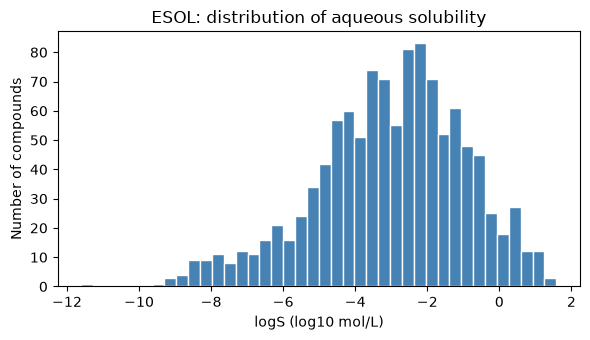

In [13]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(esol["logS"], bins=40, color="steelblue", edgecolor="white")
ax.set_xlabel("logS (log10 mol/L)")
ax.set_ylabel("Number of compounds")
ax.set_title("ESOL: distribution of aqueous solubility")
plt.tight_layout()
plt.show()

## 8. Saving results

`to_csv` writes a table back to disk. Here we write to a temporary folder so the course folder stays clean.

In [14]:
import tempfile
out = os.path.join(tempfile.gettempdir(), "esol_low_solubility.csv")
esol[esol["solubility_class"] == "low (logS < -4)"].to_csv(out, index=False)
print("saved", out)

saved /tmp/esol_low_solubility.csv


### ✏️ Exercise 1

How many ESOL compounds have a logS greater than 0 (i.e. solubility above 1 mol/L)?

*Hint:* a boolean Series can be summed: `True` counts as 1.

In [15]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
n = (esol["logS"] > 0).sum()
print(n)
```

</details>

### ✏️ Exercise 2

List the names (`compound_id`) of the 5 **least** soluble compounds.

In [16]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
esol.nsmallest(5, "logS")[["compound_id", "logS"]]
```

</details>

### ✏️ Exercise 3

What is the median logS of compounds whose name contains `chloro`? Compare it with the median of the whole dataset.

In [17]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
chloro = esol[esol["compound_id"].str.contains("chloro", case=False)]
print(len(chloro), "chloro compounds")
print("median logS (chloro):", chloro["logS"].median())
print("median logS (all):   ", esol["logS"].median())
```

</details>

## Key takeaways

- `pd.read_csv` → `DataFrame`; `.head()`, `.info()`, `.describe()` are your first three commands on any new dataset.
- Boolean masks filter rows; vectorized operations create columns without loops.
- `pd.cut` + `groupby().agg()` summarizes compound classes in one line.

**Next:** [02 · RDKit basics](02_rdkit_basics.ipynb), where the SMILES strings become real molecules.